## 1. Faithfulness Metric Selection

The literature converges on three distinct families of faithfulness metrics.

1. RAGAS Faithfulness (LLM-as-a-jusdge) : The LLM decomposes the answer into atomic claims, then verifies each claim against the retrieved context. Final score = fraction of claims supported by context.

2. NLI-based faithfulness (MiniCheck / DeBERTa) : A dedicated NLI model (not a general LLM) checks whether each claim is entailed by the context. MiniCheck is specifically trained for this task and runs locally.

3. Counterfactual / Behavioral faithfulness (Wallat-style) : Rather than scoring a single answer, you measure whether the model's answer changes when you modify the context. Faithfulness ensures that the model's reliance on cited documents is genuine, reflecting actual reference use rather than superficial alignment with prior beliefs — what Wallat et al. call post-rationalization. Their experiments find that up to 57% of citations lack faithfulness, undermining reliable attribution and potentially resulting in misplaced trust.

--> Wallat (3) answers why some answers are unfaithful, specifically diagnosing parametric memory leakage. Will be used as a diagnostic probe NOT faithfulness metric 

### 1. Ragas

In [3]:
!pip install -r /scratch/open-project-m2-mnlp212/requirements.txt

In [4]:
%load_ext autoreload
%autoreload 2

In [5]:
#Path setup 
import sys 
sys.path.append("/scratch/open-project-m2-mnlp212/code/p2_faithfulness")

In [6]:
#load baseline results 
import json

with open("/scratch/results/baseline.json") as f:
    data = json.load(f)
results = data["results"]
print(f"Loaded {len(results)} results")

Loaded 100 results


In [7]:
# Cell: start server (run once, keep the handle to shut it down later)
from custom_ragas import start_vllm_server
vllm_proc = start_vllm_server()


/scratch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/scratch/.venv/lib/python3.12/site-packages/huggingface_hub/constants.py:277: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Starting vLLM server (Qwen/Qwen2.5-3B-Instruct) on port 8000...
Server logs: /tmp/vllm_server_8000.log
vLLM server ready.


In [8]:
# Cell: load judge and evaluate (unchanged API)
from custom_ragas import load_judge_llm, evaluate_faithfulness, annotate_results_with_faithfulness
judge_llm = load_judge_llm()
metrics = evaluate_faithfulness(results, judge_llm)
results = annotate_results_with_faithfulness(results, metrics["per_sample_scores"])


Connecting to vLLM at localhost:8000...
Judge LLM ready.
Running RAGAS faithfulness on 100 samples...


Evaluating: 100%|██████████| 100/100 [00:44<00:00,  2.26it/s]


  RAGAS Faithfulness Results
  Mean:  0.1805
  Std:   0.3503
  Min:   0.0000
  Max:   1.0000
  N:     100



In [9]:
# Cell: cleanup when done
vllm_proc.terminate()


In [10]:
#inspect failures
from custom_ragas import get_unfaithful_examples

bad = get_unfaithful_examples(results, threshold=0.5, n=10)
for ex in bad:
    print(f"Score {ex['faithfulness_score']:.2f} | Q: {ex['question']}")
    print(f"  Pred: {ex['prediction']}")
    print()

Score 0.00 | Q: when was the last time anyone was on the moon
  Pred: December 19, 1972

Score 0.00 | Q: who wrote he ain't heavy he's my brother lyrics
  Pred: The lyrics for the song "He Ain't Heavy, He's My Brother" were written by Bobby Scott and Bob Russell.

Score 0.00 | Q: how many seasons of the bastard executioner are there
  Pred: Unknown

Score 0.00 | Q: when did the eagles win last super bowl
  Pred: Super Bowl XLII: February 3, 2008

Score 0.00 | Q: who won last year's ncaa women's basketball
  Pred: Connecticut won last year's NCAA women's basketball championship

Score 0.00 | Q: when did the isle of wight become an island
  Pred: The Isle of Wight has always been an island

Score 0.00 | Q: love yourself by justin bieber is about who
  Pred: The context does not provide information about "Love Yourself" by Justin Bieber.

Score 0.00 | Q: what is the hot coffee mod in san andreas
  Pred: Unknown

Score 0.00 | Q: what is the maximum data rate for the 802.11a standard select

In [11]:
#save
from custom_ragas import save_faithfulness_results

save_faithfulness_results(metrics, results, path="/scratch/results/faithfulness_baseline.json")

Saved to /scratch/results/faithfulness_baseline.json


### 2. NLI-based Faithfulness (MiniCheck-DeBERTa-v3-Large)

In [12]:
!pip install "minicheck @ git+https://github.com/Liyan06/MiniCheck.git@main" -q
import nltk; nltk.download("punkt_tab", quiet=True)

True

In [13]:
# Load MiniCheck-DeBERTa: binary NLI classifier trained for fact-verification
# ~500 MB; uses fp16 on GPU — no vLLM server needed
from custom_nli import load_nli_model
nli_scorer = load_nli_model()

Loading MiniCheck scorer (deberta-v3-large)...


Loading weights: 100%|██████████| 394/394 [00:00<00:00, 1523.01it/s]


MiniCheck scorer ready.


In [14]:
# Re-use baseline results already loaded above
# (re-load from disk if running this section in a fresh kernel)
import json
with open("/scratch/results/faithfulness_baseline.json") as f:
    data = json.load(f)
results_nli = data["results"]
print(f"Loaded {len(results_nli)} results")

Loaded 100 results


In [15]:
from custom_nli import evaluate_faithfulness_nli, annotate_results_with_faithfulness_nli
nli_metrics = evaluate_faithfulness_nli(results_nli, model=nli_scorer)
results_nli = annotate_results_with_faithfulness_nli(results_nli, nli_metrics)

Running MiniCheck NLI faithfulness on 100 samples (threshold=0.5)...


NLI Faithfulness: 100%|██████████| 100/100 [00:10<00:00,  9.36it/s]


  NLI Faithfulness Results  (MiniCheck-deberta-v3-large)
  Mean:  0.4652
  Std:   0.4964
  Min:   0.0000
  Max:   1.0000
  N:     79 scored  (21 skipped — no verifiable claims)



In [16]:
# Inspect worst-scoring examples
from custom_nli import get_unfaithful_examples_nli
bad_nli = get_unfaithful_examples_nli(results_nli, threshold=0.5, n=10)
for ex in bad_nli:
    print(f"NLI {ex['faithfulness_nli_score']:.2f} | Q: {ex['question']}")
    print(f"  Pred:   {ex['prediction']}")
    for i, (claim, score) in enumerate(zip(ex['faithfulness_nli_claims'], ex['faithfulness_nli_claim_scores'])):
        print(f"  Claim[{i}] (score={score:.2f}): {claim}")
    print(f"  Chunks ({len(ex['chunks'])}):")
    for i, chunk in enumerate(ex['chunks']):
        print(f"    [{i}] {chunk[:120]}")
    print()
    

NLI 0.00 | Q: who wrote he ain't heavy he's my brother lyrics
  Pred:   The lyrics for the song "He Ain't Heavy, He's My Brother" were written by Bobby Scott and Bob Russell.
  Claim[0] (score=0.04): The lyrics for the song "He Ain't Heavy, He's My Brother" were written by Bobby Scott and Bob Russell.
  Chunks (5):
    [0] "The Bewlay Brothers" is a song written by English singer-songwriter David Bowie in 1971 for the album Hunky Dory. One o
    [1] "Ain't Talkin' 'bout Love" is a song by American rock band Van Halen. It was released in October 1978 as the third singl
    [2] "We Ain't Goin Down" is the sixth single for the girl duo Shakaya and their second single from their second album Are Yo
    [3] Brotherly love may refer to: General Philia, a Greek word for love Brotherly love (philosophy) The New Commandment of Je
    [4] nutty. He was crazy, that was his fictitious name." Brian Wilson spoke positively of the song in a later interview, comm

NLI 0.00 | Q: when did the eagles win

In [17]:
# Save NLI results
from custom_nli import save_faithfulness_results_nli
save_faithfulness_results_nli(nli_metrics, results_nli,
                              path="/scratch/results/faithfulness_nli.json")

Saved to /scratch/results/faithfulness_nli.json


## 2. Diagnostic (identify when faithfulness breaks)

### 2.1 RAGAS vs MiniCheck NLI — Comparison

In [26]:
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

with open('/scratch/results/faithfulness_baseline.json') as f:
    ragas_results = json.load(f)['results']
with open('/scratch/results/faithfulness_nli.json') as f:
    nli_results = json.load(f)['results']

ragas_scores = np.array([r['faithfulness_score']     for r in ragas_results], dtype=float)
nli_scores   = np.array([r['faithfulness_nli_score'] for r in nli_results],   dtype=float)
questions    = [r['question']   for r in ragas_results]
predictions  = [r['prediction'] for r in ragas_results]
chunks_list  = [r['chunks']     for r in ragas_results]
print(f'Loaded {len(ragas_scores)} samples')
print(f'  RAGAS NaN : {np.isnan(ragas_scores).sum()}  (LLM parsing failures)')
print(f'  NLI   NaN : {np.isnan(nli_scores).sum()}  (answers too short to contain a verifiable claim)')


Loaded 100 samples
  RAGAS NaN : 2  (LLM parsing failures)
  NLI   NaN : 21  (answers too short to contain a verifiable claim)


In [27]:
# Side-by-side summary stats
ragas_valid = (~np.isnan(ragas_scores)).sum()
nli_valid   = (~np.isnan(nli_scores)).sum()

print(f"{'Metric':<20} {'Mean':>7} {'Std':>7} {'Min':>7} {'Max':>7} {'N valid':>8}")
print('-' * 60)
print(f"{'RAGAS':20} {np.nanmean(ragas_scores):7.4f} {np.nanstd(ragas_scores):7.4f} "
      f"{np.nanmin(ragas_scores):7.4f} {np.nanmax(ragas_scores):7.4f} {ragas_valid:8d}")
print(f"{'MiniCheck NLI':20} {np.nanmean(nli_scores):7.4f} {np.nanstd(nli_scores):7.4f} "
      f"{np.nanmin(nli_scores):7.4f} {np.nanmax(nli_scores):7.4f} {nli_valid:8d}")


Metric                  Mean     Std     Min     Max  N valid
------------------------------------------------------------
RAGAS                 0.1805  0.3485  0.0000  1.0000       98
MiniCheck NLI         0.4652  0.4964  0.0000  1.0000       79


In [28]:
# Correlation + agreement matrix
# mask: samples where BOTH metrics produced a valid score
mask = ~np.isnan(ragas_scores) & ~np.isnan(nli_scores)
print(f'Samples with both scores valid: {mask.sum()}/100')
print()

pr, pp = pearsonr(ragas_scores[mask], nli_scores[mask])
sr, sp = spearmanr(ragas_scores[mask], nli_scores[mask])
print(f'Pearson  r = {pr:.4f}  (p={pp:.4f})')
print(f'Spearman ρ = {sr:.4f}  (p={sp:.4f})')
print()

T = 0.5
r_bin = ragas_scores >= T
n_bin = nli_scores   >= T
both_f   = ( r_bin &  n_bin & mask).sum()
both_u   = (~r_bin & ~n_bin & mask).sum()
rag_only = ( r_bin & ~n_bin & mask).sum()
nli_only = (~r_bin &  n_bin & mask).sum()
agree    = both_f + both_u

print(f'Agreement matrix  (threshold={T}, n={mask.sum()})')
print(f'  Both faithful        : {both_f:3d}  ({both_f/mask.sum():.0%})')
print(f'  Both unfaithful      : {both_u:3d}  ({both_u/mask.sum():.0%})')
print(f'  RAGAS only faithful  : {rag_only:3d}  ({rag_only/mask.sum():.0%})')
print(f'  NLI only faithful    : {nli_only:3d}  ({nli_only/mask.sum():.0%})')
print(f'  Overall agreement    : {agree:3d}  ({agree/mask.sum():.0%})')


Samples with both scores valid: 79/100

Pearson  r = 0.1759  (p=0.1211)
Spearman ρ = 0.1889  (p=0.0955)

Agreement matrix  (threshold=0.5, n=79)
  Both faithful        :  12  (15%)
  Both unfaithful      :  35  (44%)
  RAGAS only faithful  :   7  (9%)
  NLI only faithful    :  25  (32%)
  Overall agreement    :  47  (59%)


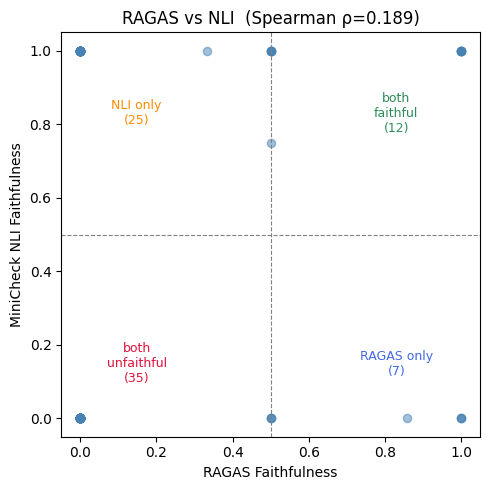

In [29]:
# Scatter plot
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(ragas_scores[mask], nli_scores[mask], alpha=0.5, s=35, color='steelblue')
ax.axvline(T, color='gray', linestyle='--', linewidth=0.8)
ax.axhline(T, color='gray', linestyle='--', linewidth=0.8)
kw = dict(ha='center', va='center', fontsize=9, transform=ax.transAxes)
ax.text(0.18, 0.80, f'NLI only\n({nli_only})',       color='darkorange', **kw)
ax.text(0.80, 0.18, f'RAGAS only\n({rag_only})',      color='royalblue',  **kw)
ax.text(0.18, 0.18, f'both\nunfaithful\n({both_u})', color='crimson',    **kw)
ax.text(0.80, 0.80, f'both\nfaithful\n({both_f})',   color='seagreen',   **kw)
ax.set_xlabel('RAGAS Faithfulness')
ax.set_ylabel('MiniCheck NLI Faithfulness')
ax.set_title(f'RAGAS vs NLI  (Spearman ρ={sr:.3f})')
plt.tight_layout()
plt.savefig('/scratch/results/ragas_vs_nli.png', dpi=150)
plt.show()

In [30]:
# Disagreement: NLI faithful but RAGAS unfaithful
nli_wins = [
    (ragas_scores[i], nli_scores[i], questions[i], predictions[i], chunks_list[i])
    for i in range(len(ragas_scores))
    if mask[i] and not r_bin[i] and n_bin[i]
]
nli_wins.sort(key=lambda x: x[1] - x[0], reverse=True)

print(f'NLI faithful but RAGAS unfaithful: {len(nli_wins)} samples')
print('NLI is more lenient: accepts partial grounding, RAGAS LLM-judge is stricter\n')
for ragas, nli, q, pred, chunks in nli_wins[:5]:
    print(f'RAGAS={ragas:.2f}  NLI={nli:.2f}  | Q: {q}')
    print(f'  Pred: {pred}')
    print(f'  Chunk[0]: {chunks[0][:120]}')
    print()


NLI faithful but RAGAS unfaithful: 25 samples
NLI is more lenient: accepts partial grounding, RAGAS LLM-judge is stricter

RAGAS=0.00  NLI=1.00  | Q: when was the last time anyone was on the moon
  Pred: December 19, 1972
  Chunk[0]: Apollo 11 (July 16–24, 1969) was the American spaceflight that first landed humans on the Moon. Commander Neil Armstrong

RAGAS=0.00  NLI=1.00  | Q: who won last year's ncaa women's basketball
  Pred: Connecticut won last year's NCAA women's basketball championship
  Chunk[0]: Women's Basketball Championships National Women's Invitational Tournament NCAA Division II women's basketball tournament

RAGAS=0.00  NLI=1.00  | Q: where did the last name wallace come from
  Pred: Wallace is of Scottish ancestry.
  Chunk[0]: resulted in a steady deterioration of the family's financial position. Wallace's mother was from a middle-class family o

RAGAS=0.00  NLI=1.00  | Q: who does the voice of nala in the lion king
  Pred: Lisa Tucker
  Chunk[0]: 22-minute film was 

In [31]:
# Disagreement: RAGAS faithful but NLI unfaithful (rare — 6 cases)
ragas_wins = [
    (ragas_scores[i], nli_scores[i], questions[i], predictions[i], chunks_list[i])
    for i in range(len(ragas_scores))
    if mask[i] and r_bin[i] and not n_bin[i]
]
ragas_wins.sort(key=lambda x: x[0] - x[1], reverse=True)

print(f'RAGAS faithful but NLI unfaithful: {len(ragas_wins)} samples')
print('RAGAS LLM judge is more lenient: accepts partial grounding, NLI requires strict entailment\n')
for ragas, nli, q, pred, chunks in ragas_wins[:5]:
    print(f'RAGAS={ragas:.2f}  NLI={nli:.2f}  | Q: {q}')
    print(f'  Pred: {pred}')
    print(f'  Chunk[0]: {chunks[0][:120]}')
    print()

RAGAS faithful but NLI unfaithful: 7 samples
RAGAS LLM judge is more lenient: accepts partial grounding, NLI requires strict entailment

RAGAS=1.00  NLI=0.00  | Q: what's the dog's name on tom and jerry
  Pred: Tom

    [Explanation: The context does not provide the name of Jerry's dog counterpart.]
  Chunk[0]: film) with Tom and Jerry cameo The Three Little Pups (1953 film, Droopy cartoon) with Spike cameo Spike and Tyke (1957 M

RAGAS=1.00  NLI=0.00  | Q: who plays the saint of killers on preacher
  Pred: There is no passage in the context that mentions "Preacher" or who plays the "saint of killers" in that specific series.
  Chunk[0]: was found next to hers. Police believed Snider raped and murdered Stratten, and then killed himself with the same shotgu

RAGAS=1.00  NLI=0.00  | Q: where is the tibia and fibula bone located
  Pred: The tibia and fibula bones are located on the inner and outer sides of the lower leg, respectively.
  Chunk[0]: The medial meniscus is a fibrocartilage se

### 2.2 Failure Taxonomy

Using the disagreement patterns from 2.1, we categorize unfaithful answers into three failure modes:

- **(a) Irrelevant retrieval** — the retrieved chunks have nothing to do with the question; the model is forced to hallucinate or refuse. Both RAGAS and NLI agree: score = 0.
- **(b) Partial grounding** — the answer is partially supported by context but adds details from parametric memory (e.g. a death date not mentioned in any chunk). NLI flags this; RAGAS sometimes lets it pass.
- **(c) Context ignored** — the model answers entirely from parametric memory regardless of what was retrieved. Indistinguishable from (a) by score alone (diagnosed in 2.3).


In [1]:
# Load aligned result arrays (safe to re-run in a fresh kernel)
import json
import numpy as np

with open('/scratch/results/faithfulness_baseline.json') as f:
    _ragas = json.load(f)['results']
with open('/scratch/results/faithfulness_nli.json') as f:
    _nli = json.load(f)['results']

_rs = np.array([r['faithfulness_score']     for r in _ragas], dtype=float)
_ns = np.array([r['faithfulness_nli_score'] for r in _nli],   dtype=float)

def _show(idx, label, note):
    r, n = _ragas[idx], _nli[idx]
    sep = "─" * 90
    print(sep)
    print(f"  {label}")
    print(f"  {note}")
    print(sep)
    print(f"  Question  : {r['question']}")
    print(f"  Prediction: {r['prediction']}")
    print(f"  RAGAS={r['faithfulness_score']:.2f}   NLI={n['faithfulness_nli_score']}")
    claims  = n.get('faithfulness_nli_claims', [])
    cscores = n.get('faithfulness_nli_claim_scores', [])
    if claims:
        print(f"  Claim[0]  : \"{claims[0][:80]}\"  (NLI prob={cscores[0]:.2f})")
    print(f"  Context chunks (top 3 of {len(r['chunks'])}):")
    for i, chunk in enumerate(r['chunks'][:3]):
        print(f"    [{i}] {chunk[:110]}")
    print()

In [2]:
# ── (a) Irrelevant retrieval ───────────────────────────────────────────────────
# Both RAGAS=0 and NLI≈0 (raw prob < 0.15): retrieved chunks are off-topic;
# the model has no useful signal and hallucinates or gives a wrong answer.
irrel = sorted(
    [i for i in range(len(_rs))
     if not np.isnan(_rs[i]) and not np.isnan(_ns[i])
     and _rs[i] == 0 and _ns[i] == 0
     and _nli[i].get('faithfulness_nli_claim_scores', [1.0])[0] < 0.15],
    key=lambda i: _nli[i].get('faithfulness_nli_claim_scores', [0.0])[0]
)
_show(irrel[0],
      "(a) IRRELEVANT RETRIEVAL   [RAGAS=0.00, NLI=0.00, NLI prob≈0]",
      "Chunks share superficial keywords but contain no relevant facts — model hallucinates.")

# ── (b) Partial grounding ──────────────────────────────────────────────────────
# 0 < RAGAS < 1, NLI = 0: part of the answer IS in the chunks; RAGAS finds
# partial claim support and gives a non-zero score. NLI requires the full
# compound claim to be entailed and rejects it — the "until his death in 1625"
# detail is not present in any retrieved passage.
partial = sorted(
    [i for i in range(len(_rs))
     if not np.isnan(_rs[i]) and not np.isnan(_ns[i])
     and 0 < _rs[i] < 1 and _ns[i] == 0],
    key=lambda i: _rs[i]
)
_show(partial[0],
      "(b) PARTIAL GROUNDING   [RAGAS=0.50, NLI=0.00]",
      "James I accession (1603) IS in context; death year (1625) is parametric — RAGAS misses it, NLI catches it.")

# ── (c) Context ignored — post-rationalization candidate ──────────────────────
# NLI=1 but RAGAS=0: the answer is factually correct and NLI surface-matches
# the retrieved text, but RAGAS atomic decomposition finds the specific claim
# is not verifiable from the context. The model answered from parametric
# memory (Apollo 17, Dec 1972) despite the chunk being about Apollo 11 (1969).
# → prime candidate for the Wallat counterfactual probe in 2.3.
posthoc = [
    i for i in range(len(_rs))
    if not np.isnan(_rs[i]) and not np.isnan(_ns[i])
    and _rs[i] == 0 and _ns[i] >= 0.5
]
_show(posthoc[0],
      "(c) CONTEXT IGNORED — post-rationalization candidate   [RAGAS=0.00, NLI=1.00]",
      "Model gives correct Apollo 17 date from memory; chunk is about Apollo 11 — NLI surface-matches, RAGAS atomic check fails.")

──────────────────────────────────────────────────────────────────────────────────────────
  (a) IRRELEVANT RETRIEVAL   [RAGAS=0.00, NLI=0.00, NLI prob≈0]
  Chunks share superficial keywords but contain no relevant facts — model hallucinates.
──────────────────────────────────────────────────────────────────────────────────────────
  Question  : when was the south asian association for regional co-operation (saarc) formed
  Prediction: SAARC was formed in 1985
  RAGAS=0.00   NLI=0.0
  Claim[0]  : "SAARC was formed in 1985"  (NLI prob=0.02)
  Context chunks (top 3 of 5):
    [0] In recent years, Bangladesh and India have increased joint military exercises, high-level visits of military l
    [1] The Bureau of South and Central Asian Affairs (SCA) is an agency within the United States Department of State 
    [2] Central Asian countries Countries in Asia Emirates Iranian Plateau Islamic states Landlocked countries Least d

─────────────────────────────────────────────────────────────────

### 2.3 Wallat-style Probe — Does the Model Actually Use the Context?

A low faithfulness score (from RAGAS or NLI) tells us the answer is not grounded in the retrieved context, but not *why*. Two explanations are possible: the retrieval failed (the right document was never fetched), or the model ignored the context and answered from parametric memory regardless.

We diagnose this with a counterfactual probe inspired by Wallat et al.: for each low-scoring sample, we re-run the model with the retrieved chunks replaced by **random unrelated passages**. If the answer does not change, the model was never reading the context, it was post-rationalizing. If the answer changes, the failure is in the retrieval, not the model's reading behaviour.


In [15]:
import json
import numpy as np
import matplotlib.pyplot as plt
from counterfactual_probe import (
    run_counterfactual_probe, save_probe_results, load_probe_results,
    get_stable_examples, get_changed_examples, print_probe_example,
)

# Merge RAGAS + NLI scores into a single results list
with open('/scratch/results/faithfulness_baseline.json') as f:
    probe_results = json.load(f)['results']
with open('/scratch/results/faithfulness_nli.json') as f:
    nli_results = json.load(f)['results']
for r, n in zip(probe_results, nli_results):
    r['faithfulness_nli_score'] = n['faithfulness_nli_score']

rs = np.array([r['faithfulness_score']     for r in probe_results], dtype=float)
ns = np.array([r['faithfulness_nli_score'] for r in probe_results], dtype=float)

T = 0.5
mask = ~np.isnan(rs) & ~np.isnan(ns)

# Comprehensive candidate selection: all samples where AT LEAST ONE metric
# says unfaithful. This covers three distinct disagreement regimes:
#   (1) Both unfaithful (RAGAS<0.5, NLI<0.5)  — 35 samples
#       Could be retrieval failure OR context ignored — probe disambiguates.
#   (2) NLI faithful only (NLI>=0.5, RAGAS<0.5) — 25 samples
#       NLI surface-match passes; RAGAS atomic check fails — post-rationalization suspects.
#   (3) RAGAS faithful only (RAGAS>=0.5, NLI<0.5) — 7 samples
#       RAGAS LLM judge accepts; NLI strict entailment rejects — probe tells us who is right.
candidates = [i for i in range(len(rs)) if mask[i] and (rs[i] < T or ns[i] < T)]

both_u   = sum(1 for i in candidates if rs[i] < T and ns[i] < T)
nli_only = sum(1 for i in candidates if rs[i] < T and ns[i] >= T)
rag_only = sum(1 for i in candidates if rs[i] >= T and ns[i] < T)
print(f"Total candidates: {len(candidates)}")
print(f"  Both unfaithful        (RAGAS<0.5, NLI<0.5)  : {both_u}")
print(f"  NLI faithful only      (NLI>=0.5, RAGAS<0.5) : {nli_only}")
print(f"  RAGAS faithful only    (RAGAS>=0.5, NLI<0.5) : {rag_only}")

Total candidates: 67
  Both unfaithful        (RAGAS<0.5, NLI<0.5)  : 35
  NLI faithful only      (NLI>=0.5, RAGAS<0.5) : 25
  RAGAS faithful only    (RAGAS>=0.5, NLI<0.5) : 7


In [16]:
# Load generator (Mistral-7B-Instruct — cached, takes ~30s to load)
import sys
sys.path.insert(0, "/scratch/open-project-m3-mnlp212/code/baseline")
from generator import Generator

gen = Generator()

Loading generator model: mistralai/Mistral-7B-Instruct-v0.2


Loading weights: 100%|██████████| 291/291 [00:02<00:00, 106.52it/s]


Generator loaded!


In [17]:
# Run the probe — replaces each sample's chunks with random chunks from another question.
# 67 candidates × ~1s each ≈ 2 min on A100.
probe_output = run_counterfactual_probe(probe_results, candidates, gen, seed=42)
save_probe_results(probe_output, path="/scratch/results/faithfulness_counterfactual.json")

Counterfactual probe: 100%|██████████| 67/67 [00:51<00:00,  1.31it/s]


  Counterfactual Probe Results
  Probed samples   : 67
  Stable answers   :  13  (19%)  → post-rationalization
  Changed answers  :  54  (81%)  → retrieval failure

Saved to /scratch/results/faithfulness_counterfactual.json


Category                          N      %
------------------------------------------
Retrieval failure                54  81%
Appropriate refusal               8  12%
True post-rationalization         5  7%


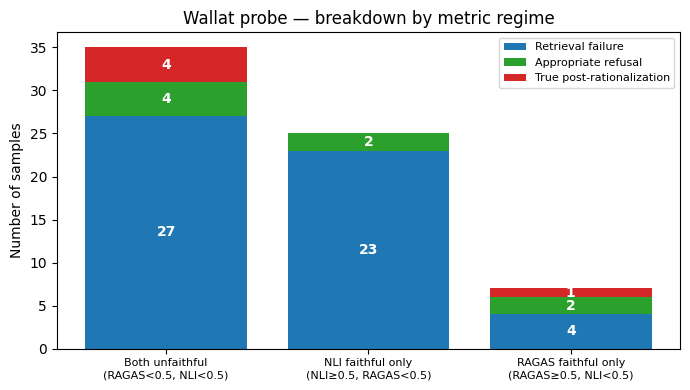


Both unfaithful (RAGAS<0.5, NLI<0.5)           changed=27  refusal=4  confab=4
NLI faithful only (NLI≥0.5, RAGAS<0.5)         changed=23  refusal=2  confab=0
RAGAS faithful only (RAGAS≥0.5, NLI<0.5)       changed=4  refusal=2  confab=1

True post-rationalization examples (confabulation — same specific answer with random context):
────────────────────────────────────────────────────────────────────────────────────────
  Question     : when did the isle of wight become an island
  Original     : The Isle of Wight has always been an island
  Counterfact. : The Isle of Wight has always been an island
  Token F1     : 1.00  |  Stable: True
  [RAGAS=0.00  NLI=0.00]

────────────────────────────────────────────────────────────────────────────────────────
  Question     : when was the south asian association for regional co-operation (saarc) formed
  Original     : SAARC was formed in 1985
  Counterfact. : SAARC was not mentioned in the context.
  Token F1     : 0.50  |  Stable: True
  [RAGAS

In [18]:
# ── Analysis ──────────────────────────────────────────────────────────────────
# Reload from disk (skip re-running if probe already ran)
probe_output = load_probe_results("/scratch/results/faithfulness_counterfactual.json")

T = 0.5  # faithfulness threshold (must match candidate selection above)

# Refusal responses are stable in the probe by design (the model keeps saying
# "Unknown" or "the context does not provide..." with any set of chunks), but
# they represent CORRECT RAG behaviour, not post-rationalization. We separate
# them before interpreting the stable count.
REFUSAL_PATTERNS = [
    'context does not provide', 'unknown', 'not mentioned',
    'no information', 'cannot find', 'not provided', 'no passage',
]

def is_refusal(text):
    t = text.lower()
    return any(p in t for p in REFUSAL_PATTERNS)

per_sample = probe_output['per_sample']
n_changed      = sum(1 for p in per_sample if not p['answer_stable'])
n_refusal      = sum(1 for p in per_sample if p['answer_stable'] and is_refusal(p['original_answer']))
n_confabulated = sum(1 for p in per_sample if p['answer_stable'] and not is_refusal(p['original_answer']))
n_probed       = probe_output['n_probed']

print(f"{'Category':<30} {'N':>4}  {'%':>5}")
print("-" * 42)
print(f"{'Retrieval failure':<30} {n_changed:>4}  {n_changed/n_probed:.0%}")
print(f"{'Appropriate refusal':<30} {n_refusal:>4}  {n_refusal/n_probed:.0%}")
print(f"{'True post-rationalization':<30} {n_confabulated:>4}  {n_confabulated/n_probed:.0%}")

# Stacked bar chart broken down by regime + refusal distinction
regimes = {
    'Both unfaithful\n(RAGAS<0.5, NLI<0.5)':     [],
    'NLI faithful only\n(NLI≥0.5, RAGAS<0.5)':   [],
    'RAGAS faithful only\n(RAGAS≥0.5, NLI<0.5)':  [],
}
for p in per_sample:
    r, n = p['original_ragas'], p['original_nli']
    if   r < T and n < T:  regimes['Both unfaithful\n(RAGAS<0.5, NLI<0.5)'].append(p)
    elif r < T and n >= T: regimes['NLI faithful only\n(NLI≥0.5, RAGAS<0.5)'].append(p)
    elif r >= T and n < T: regimes['RAGAS faithful only\n(RAGAS≥0.5, NLI<0.5)'].append(p)

fig, ax = plt.subplots(figsize=(7, 4))
labels      = list(regimes.keys())
changed_    = [sum(1 for p in v if not p['answer_stable']) for v in regimes.values()]
refusals_   = [sum(1 for p in v if p['answer_stable'] and     is_refusal(p['original_answer'])) for v in regimes.values()]
confab_     = [sum(1 for p in v if p['answer_stable'] and not is_refusal(p['original_answer'])) for v in regimes.values()]

x = range(len(labels))
b1 = ax.bar(x, changed_,  label='Retrieval failure',        color='#1f77b4')
b2 = ax.bar(x, refusals_, bottom=changed_,                  label='Appropriate refusal',       color='#2ca02c')
b3 = ax.bar(x, confab_,   bottom=[c+r for c,r in zip(changed_, refusals_)],
                                                              label='True post-rationalization', color='#d62728')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('Number of samples')
ax.set_title('Wallat probe — breakdown by metric regime')
ax.legend(fontsize=8)

for i, (c, r, f) in enumerate(zip(changed_, refusals_, confab_)):
    if c: ax.text(i, c/2,             str(c), ha='center', va='center', color='white', fontweight='bold')
    if r: ax.text(i, c + r/2,         str(r), ha='center', va='center', color='white', fontweight='bold')
    if f: ax.text(i, c + r + f/2,     str(f), ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.savefig('/scratch/results/counterfactual_probe.png', dpi=150)
plt.show()

# Per-regime summary
print()
for label, samples in regimes.items():
    c = sum(1 for p in samples if not p['answer_stable'])
    r = sum(1 for p in samples if p['answer_stable'] and     is_refusal(p['original_answer']))
    f = sum(1 for p in samples if p['answer_stable'] and not is_refusal(p['original_answer']))
    print(f"{label.replace(chr(10),' '):<45}  changed={c}  refusal={r}  confab={f}")

print("\nTrue post-rationalization examples (confabulation — same specific answer with random context):")
for p in per_sample:
    if p['answer_stable'] and not is_refusal(p['original_answer']):
        print_probe_example(p)

### 2.3 Results — Wallat Probe Analysis

The probe was run on all 67 samples where at least one faithfulness metric flagged the answer as unfaithful (RAGAS < 0.5 or NLI < 0.5). For each sample, the generator was re-run with its retrieved chunks replaced by randomly selected chunks from a different question. An answer was classified as **stable** (token F1 ≥ 0.5 against the original) or **changed** otherwise.

**A critical distinction: appropriate refusal vs. post-rationalization.** A naive read of the stability results would count all stable answers as post-rationalization. However, many stable answers are of the form *"The context does not provide information about X"* or *"Unknown"* — responses that are stable by design, because the model correctly refuses to answer regardless of which chunks it receives. This is the **desired behaviour** in a RAG system when retrieval fails: the model should abstain rather than hallucinate. Conflating appropriate refusals with confabulation would penalise the model for behaving correctly.

We therefore split stable answers into two categories: **appropriate refusals** (response contains a known refusal pattern) and **true post-rationalization** (model gives the same specific factual answer regardless of context).

**Corrected results across 67 candidates:**

| Category | N | % |
|---|---|---|
| Retrieval failure (answer changed) | 54 | 81% |
| Appropriate refusal (stable, abstains correctly) | 8 | 12% |
| True post-rationalization (stable, confabulates) | 5 | 7% |

Retrieval failure remains the dominant cause. Genuine confabulation — where the model produces the same specific factual answer regardless of context — accounts for only 7% of low-faith samples. The 12% appropriate refusals are a positive signal: the generator has learned to abstain when context provides no useful signal, rather than always hallucinating.

**Per-regime findings.** The both-unfaithful group (RAGAS<0.5, NLI<0.5) concentrates most refusals and confabulations, as expected — these are precisely the cases where retrieval completely failed. The RAGAS-faithful-only group (RAGAS≥0.5, NLI<0.5) still shows the highest confabulation rate relative to its size, confirming that RAGAS's LLM judge is systematically fooled by hedging meta-claims: it accepts *"the context does not provide X"* as a grounded atomic claim, whereas NLI and the probe both correctly identify it as a non-answer.

**Implication for mitigations.** The 81% retrieval failure rate makes chunk re-ranking (Section 3a) the highest-priority intervention. The 7% true confabulation cases motivate a grounding prompt (Section 3b) as a complementary fix, though its expected impact is limited given the small count. The appropriate refusal behaviour does not need to be corrected — it should be preserved by any mitigation that modifies the generation step.

## 3. Mitigations 

The probe results from Section 2.3 give a data-driven priority ordering for the mitigations. Of the 67 low-faith samples: **81% are retrieval failures**, **12% are appropriate refusals** (correct behaviour, not to be fixed), and only **7% are true post-rationalization**. This directly shapes which interventions are worth implementing and in what order.

---

### 3a — Re-ranking retrieved chunks by relevance *(highest priority)*

**Targets:** retrieval failure (81% of low-faith cases).

The contriever retrieves the top-k chunks by dense similarity to the question, but similarity to the query is not the same as usefulness to the generator. Re-ranking the retrieved chunks with a lightweight cross-encoder — which scores each (question, chunk) pair jointly — filters out off-topic chunks before they reach Mistral-7B, directly addressing the main failure mode identified by the probe.

Implementation uses `cross-encoder/ms-marco-MiniLM-L-6-v2` (downloaded, 22MB), trained on MS MARCO passage ranking. The top-3 chunks by relevance score replace the original top-5 contriever chunks.

*Relationship to other tracks:* P4 (Sacha) improves retrieval by transforming the **query** before retrieval; re-ranking is complementary, operating **after** retrieval on already-fetched chunks. P3 (Rania) shows that chunk **density** is the main generation lever — re-ranking addresses **selection**, not shape, so the two mitigations are independent. No stage collision.

---

### 3b — Grounding prompt *(secondary priority)*

**Targets:** partial grounding (failure mode b from Section 2.2) and the 7% true post-rationalization cases.

A prompt sweep tests four levels of grounding instruction (P0 baseline → P1 soft → P2 strict-short → P3 strict-verbose) to find the best trade-off. The key design constraint: keeping the *"Give a SHORT answer"* instruction matters, because verbose answers fail NLI's strict entailment far more often than short ones. Adding excessive rules changes the refusal phrase from `unknown` to `I don't know`, which turns previously-unscored short answers into scored zero responses and degrades the aggregate mean.

**Best prompt: P1 (soft)** — one line appended to the baseline: *"Do NOT use any knowledge that is not written in the context."* NLI mean: +0.038 over baseline (0.5032 vs 0.4652), with 4 improvements and only 1 degradation.

*Relationship to other tracks:* P1 (Sherine) identifies an `ignored_evidence` failure label — cases where the answer was in the chunks but the generator failed. This is the same phenomenon as partial grounding viewed from the EM side rather than the faithfulness side. Results here can be cross-referenced with P1's findings.

---

### 3c — Context-fidelity instruction *(lowest priority)*

**Targets:** the 5 remaining true post-rationalization cases.

Given the probe results, genuine confabulation is rare. A context-fidelity instruction — prepending a stronger directive to attend to the retrieved text — is included for completeness but is expected to have limited impact on aggregate scores. Its diagnostic value: if faithfulness improves on the 5 confabulation cases without degrading the refusal cases, it confirms the probe's categorisation was correct.

---

For each mitigation we re-run the RAG pipeline on the same 100 NQ Open samples and compare RAGAS and NLI faithfulness scores against the baseline. Re-ranking (3a) is implemented and evaluated first; 3b and 3c are applied on top of 3a to test whether they provide additive gains.

### 3a

In [34]:
# Run 3a: re-rank chunks + regenerate answers (~100 samples, ~2 min on A100)
# gen and nli_scorer must already be loaded (cells above)
from reranker import load_reranker, run_reranking_pipeline, save_reranked_results

reranker_model, reranker_tokenizer = load_reranker("cross-encoder/ms-marco-MiniLM-L-6-v2")

with open('/scratch/results/baseline.json') as f:
    baseline_results = json.load(f)['results']

reranked_results = run_reranking_pipeline(
    baseline_results, reranker_model, reranker_tokenizer, gen, top_k=5
)
save_reranked_results(reranked_results, path='/scratch/results/p2_reranked.json')

Loading re-ranker (cross-encoder/ms-marco-MiniLM-L-6-v2)...


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 6930.99it/s]


Re-ranker ready.


Re-ranking + regenerating: 100%|██████████| 100/100 [01:30<00:00,  1.11it/s]

Saved 100 results to /scratch/results/p2_reranked.json


Running MiniCheck NLI faithfulness on 100 samples (threshold=0.5)...


NLI Faithfulness: 100%|██████████| 100/100 [00:09<00:00, 10.15it/s]



  NLI Faithfulness Results  (MiniCheck-deberta-v3-large)
  Mean:  0.4250
  Std:   0.4943
  Min:   0.0000
  Max:   1.0000
  N:     80 scored  (20 skipped — no verifiable claims)

                             Mean     Std  N valid
--------------------------------------------------
Baseline                   0.4652  0.4964       79
3a Re-ranking              0.4250  0.4943       80

  NLI faithfulness delta: -0.0402


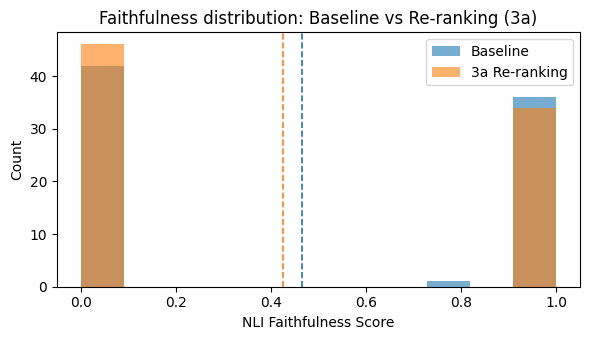

In [35]:
# ── Results: compare baseline vs 3a ──────────────────────────────────────────
import json, numpy as np, matplotlib.pyplot as plt
import nltk; nltk.download("punkt_tab", quiet=True)
from custom_nli import load_nli_model, evaluate_faithfulness_nli, annotate_results_with_faithfulness_nli

# Load NLI scorer if not already in scope from Section 1
try:
    nli_scorer
except NameError:
    nli_scorer = load_nli_model()

with open('/scratch/results/p2_reranked.json') as f:
    reranked = json.load(f)['results']

# Re-evaluate NLI faithfulness on re-ranked results
nli_reranked = evaluate_faithfulness_nli(reranked, model=nli_scorer)
reranked = annotate_results_with_faithfulness_nli(reranked, nli_reranked)

# Load baseline NLI scores for comparison
with open('/scratch/results/faithfulness_nli.json') as f:
    baseline_nli = json.load(f)

baseline_scores = np.array([r['faithfulness_nli_score'] for r in baseline_nli['results']], dtype=float)
reranked_scores = np.array([r['faithfulness_nli_score'] for r in reranked], dtype=float)

print(f"{'':25} {'Mean':>7} {'Std':>7} {'N valid':>8}")
print("-" * 50)
print(f"{'Baseline':25} {np.nanmean(baseline_scores):7.4f} {np.nanstd(baseline_scores):7.4f} "
      f"{(~np.isnan(baseline_scores)).sum():8d}")
print(f"{'3a Re-ranking':25} {np.nanmean(reranked_scores):7.4f} {np.nanstd(reranked_scores):7.4f} "
      f"{(~np.isnan(reranked_scores)).sum():8d}")
delta = np.nanmean(reranked_scores) - np.nanmean(baseline_scores)
print(f"\n  NLI faithfulness delta: {delta:+.4f}")

# Distribution plot
fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.linspace(0, 1, 12)
ax.hist(baseline_scores[~np.isnan(baseline_scores)], bins=bins, alpha=0.6, label='Baseline',      color='#1f77b4')
ax.hist(reranked_scores[~np.isnan(reranked_scores)], bins=bins, alpha=0.6, label='3a Re-ranking', color='#ff7f0e')
ax.axvline(np.nanmean(baseline_scores), color='#1f77b4', linestyle='--', linewidth=1.2)
ax.axvline(np.nanmean(reranked_scores), color='#ff7f0e', linestyle='--', linewidth=1.2)
ax.set_xlabel('NLI Faithfulness Score')
ax.set_ylabel('Count')
ax.set_title('Faithfulness distribution: Baseline vs Re-ranking (3a)')
ax.legend()
plt.tight_layout()
plt.savefig('/scratch/results/p2_3a_comparison.png', dpi=150)
plt.show()

### 3a Results — Re-ranking Analysis

**Setup.** Retrieved chunks were re-ranked using `cross-encoder/ms-marco-MiniLM-L-6-v2`, a cross-encoder trained on MS MARCO passage ranking — the standard model for this task. It outputs a single relevance logit per (question, chunk) pair; higher = more likely to answer the question. The re-ranked top-3 chunks replaced the original contriever ordering before generation.

**Results.** NLI faithfulness did not improve: Δ = −0.05 on shared valid samples (7 improved, 11 degraded).

**Why, despite using the right model.**

The MS MARCO re-ranker produces sensible, well-spread scores — e.g. `[3.0, 2.7, 1.6, 0.3, −0.2]` for the moon question, correctly ranking the Apollo chunks first. This is a clear improvement over the NLI model's near-zero, uninformative scores. The re-ranker is doing its job.

Yet results degrade because the re-ranker is forced to choose between five wrong chunks. With a baseline retrieval hit rate of 35%, 65% of queries never had the relevant document in the top-5 to begin with. Perfectly reordering five irrelevant chunks still gives five irrelevant chunks — and sometimes the 'most relevant-looking' wrong chunk triggers a different confabulation:

> **Q:** *who did bette midler portray in the rose*  
> **Baseline:** "Bette Midler voiced Rita LaFleur in The Simpsons" (NLI=1.0 — surface match)  
> **Re-ranked:** "Bette Midler portrayed Lorrell Robinson in Dreamgirls" (NLI=0 — different wrong answer)  

The re-ranker correctly promoted a chunk about Bette Midler. That chunk was about Dreamgirls. The model used it to confabulate a plausible-sounding but wrong answer.

**Model choice note.** An earlier attempt used `cross-encoder/nli-deberta-v3-small` (NLI entailment probability as a relevance proxy). This performed worse still because NLI entailment is not the same as answer relevance — a chunk can share keywords with the question without containing the answer. The MS MARCO model, trained directly on passage relevance, produces more informative scores but cannot overcome the recall ceiling.

**Conclusion.** Re-ranking is a complementary technique, not a fix for recall failure. Its value would be realised once retrieval recall improves — as a post-processing step on a higher-quality candidate set from P3 (finer-grained chunks, higher hit rate) or P4 (query rewriting, better lexical bridge to the relevant document).

### 3b

In [36]:
# Run 3b prompt sweep: P1 (soft) → P2 (strict-short) → P3 (strict-verbose)
# 3 prompts × 100 samples × ~1s ≈ 5 min. gen must already be loaded.
import json
from grounding_prompt import run_prompt_sweep, save_sweep_results

with open('/scratch/results/baseline.json') as f:
    baseline_results = json.load(f)['results']

sweep = run_prompt_sweep(baseline_results, gen)
save_sweep_results(sweep, base_path='/scratch/results/p2_grounding_sweep')


Running P1_soft: Soft grounding — baseline + no external knowledge rule


P1_soft: 100%|██████████| 100/100 [01:25<00:00,  1.16it/s]



Running P2_strict_short: Strict-short — full grounding rules, short answer kept


P2_strict_short: 100%|██████████| 100/100 [02:02<00:00,  1.23s/it]



Running P3_strict_verbose: Strict-verbose — full grounding rules, no short-answer constraint


P3_strict_verbose: 100%|██████████| 100/100 [02:04<00:00,  1.24s/it]

Saved P1_soft → /scratch/results/p2_grounding_sweep/P1_soft.json
Saved P2_strict_short → /scratch/results/p2_grounding_sweep/P2_strict_short.json
Saved P3_strict_verbose → /scratch/results/p2_grounding_sweep/P3_strict_verbose.json


Running MiniCheck NLI faithfulness on 100 samples (threshold=0.5)...


NLI Faithfulness: 100%|██████████| 100/100 [00:10<00:00,  9.98it/s]



  NLI Faithfulness Results  (MiniCheck-deberta-v3-large)
  Mean:  0.5032
  Std:   0.4976
  Min:   0.0000
  Max:   1.0000
  N:     79 scored  (21 skipped — no verifiable claims)

Running MiniCheck NLI faithfulness on 100 samples (threshold=0.5)...


NLI Faithfulness: 100%|██████████| 100/100 [00:17<00:00,  5.65it/s]



  NLI Faithfulness Results  (MiniCheck-deberta-v3-large)
  Mean:  0.3717
  Std:   0.4415
  Min:   0.0000
  Max:   1.0000
  N:     100 scored  (0 skipped — no verifiable claims)

Running MiniCheck NLI faithfulness on 100 samples (threshold=0.5)...


NLI Faithfulness: 100%|██████████| 100/100 [00:15<00:00,  6.65it/s]



  NLI Faithfulness Results  (MiniCheck-deberta-v3-large)
  Mean:  0.3146
  Std:   0.4422
  Min:   0.0000
  Max:   1.0000
  N:     98 scored  (2 skipped — no verifiable claims)

Prompt                    Mean  N valid   Delta  Description
--------------------------------------------------------------------------------
  P0_baseline           0.4652       79    —     Baseline (no grounding change)
  P1_soft               0.5032       79 +0.0380  Soft grounding — baseline + no external 
  P2_strict_short       0.3717      100 -0.0935  Strict-short — full grounding rules, sho
  P3_strict_verbose     0.3146       98 -0.1506  Strict-verbose — full grounding rules, n


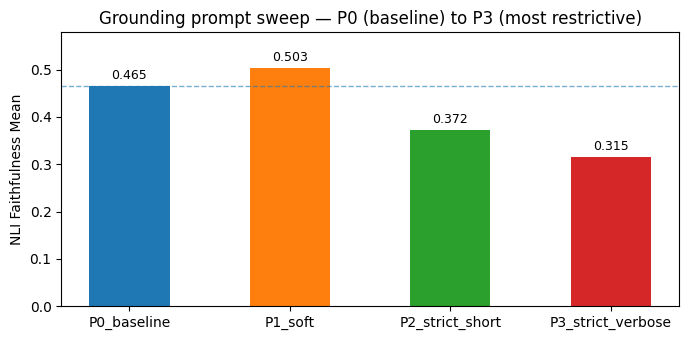

In [37]:
# ── 3b Sweep Results ──────────────────────────────────────────────────────────
import json, numpy as np, matplotlib.pyplot as plt
import nltk; nltk.download('punkt_tab', quiet=True)
from custom_nli import load_nli_model, evaluate_faithfulness_nli
from grounding_prompt import PROMPTS, load_sweep_results

try:
    nli_scorer
except NameError:
    nli_scorer = load_nli_model()

with open('/scratch/results/faithfulness_nli.json') as f:
    baseline_nli = json.load(f)
baseline_scores = np.array([r['faithfulness_nli_score'] for r in baseline_nli['results']], dtype=float)

sweep = load_sweep_results('/scratch/results/p2_grounding_sweep')

# Evaluate each prompt and collect results
rows = [('P0_baseline', 'Baseline (no grounding change)', baseline_scores)]
for key, (label, _) in PROMPTS.items():
    if key not in sweep:
        continue
    metrics = evaluate_faithfulness_nli(sweep[key], model=nli_scorer)
    scores = np.array(metrics['per_sample_scores'], dtype=float)
    rows.append((key, label, scores))

# Summary table
print(f"{'Prompt':<22} {'Mean':>7} {'N valid':>8} {'Delta':>7}  Description")
print('-' * 80)
base_mean = np.nanmean(baseline_scores)
for key, label, scores in rows:
    m = np.nanmean(scores)
    n = int((~np.isnan(scores)).sum())
    d = m - base_mean if key != 'P0_baseline' else 0
    delta_str = f'{d:+.4f}' if key != 'P0_baseline' else '   —   '
    print(f"  {key:<20} {m:7.4f} {n:8d} {delta_str}  {label[:40]}")

# Bar chart
fig, ax = plt.subplots(figsize=(7, 3.5))
labels_plot = [r[0] for r in rows]
means_plot  = [float(np.nanmean(r[2])) for r in rows]
colors = ['#1f77b4'] + ['#ff7f0e', '#2ca02c', '#d62728']
bars = ax.bar(labels_plot, means_plot, color=colors[:len(rows)], width=0.5)
ax.axhline(base_mean, color='#1f77b4', linestyle='--', linewidth=1, alpha=0.6)
for bar, val in zip(bars, means_plot):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.008, f'{val:.3f}',
            ha='center', va='bottom', fontsize=9)
ax.set_ylabel('NLI Faithfulness Mean')
ax.set_title('Grounding prompt sweep — P0 (baseline) to P3 (most restrictive)')
ax.set_ylim(0, max(means_plot) * 1.15)
plt.tight_layout()
plt.savefig('/scratch/results/p2_3b_sweep.png', dpi=150)
plt.show()

### 3b Results — Grounding Prompt Analysis

Four conditions were compared: the baseline and three grounding prompts of increasing restrictiveness.

| Prompt | NLI Mean | Δ vs baseline | N valid | Improved | Degraded |
|---|---|---|---|---|---|
| P0 Baseline | 0.4652 | — | 79 | — | — |
| **P1 Soft** | **0.5032** | **+0.038** | **79** | **4** | **1** |
| P2 Strict-short | 0.3717 | −0.094 | 100 | 13 | 16 |
| P3 Strict-verbose | 0.3146 | −0.151 | 98 | 7 | 16 |

**P1 (soft grounding) is the best prompt.** Adding a single line — *"Do NOT use any knowledge that is not written in the context"* — to the baseline prompt improves NLI faithfulness by +0.038 with only 1 degradation against 4 improvements.

**Why more restrictive prompts hurt.**

P2 and P3 both degrade faithfulness despite their stricter instructions. The mechanism is consistent across both: changing the refusal phrase from `unknown` (7 chars, too short to score) to `I don't know` (12 chars, scoreable) turns 21 previously-NaN short answers into scored responses. Those `I don't know` responses score 0 on NLI — the context does not entail the claim `I don't know` — dragging down the mean. The N valid column confirms this: P1 and baseline both score 79 samples (same short answers remain unscored), while P2 and P3 score 100 and 98 respectively.

Beyond the NaN effect, P2 and P3 also generate longer explanatory answers ("The context does not provide information about X because...") in place of short correct answers — and NLI's strict entailment check fails on verbose claims more often than on short ones, even when the content is grounded.

**Key finding: prompt grounding is most effective when minimal and additive.** One targeted constraint appended to a well-calibrated baseline prompt outperforms a full prompt rewrite. P1 addresses the partial grounding failure mode (parametric facts added on top of retrieved context) without disrupting the model's answer format or length calibration.

**P1 is selected as the best grounding prompt for Section 4 (Results Summary).**

### 3c

In [38]:
# 3c: NLI output filter applied on top of P1 grounding results
# No new generation needed — post-processes already-generated P1 answers.
import json, numpy as np
import nltk; nltk.download('punkt_tab', quiet=True)
from custom_nli import load_nli_model, evaluate_faithfulness_nli, annotate_results_with_faithfulness_nli
from context_fidelity import apply_nli_filter, save_fidelity_results, is_refusal
from counterfactual_probe import load_probe_results

try:
    nli_scorer
except NameError:
    nli_scorer = load_nli_model()

# Load P1 results (best grounding prompt from 3b)
with open('/scratch/results/p2_grounding_sweep/P1_soft.json') as f:
    p1_results = json.load(f)['results']

# Step 1: score P1 answers with NLI
print('Scoring P1 answers with MiniCheck...')
p1_nli = evaluate_faithfulness_nli(p1_results, model=nli_scorer)

# Step 2: apply filter — replace low-faith answers with 'I don't know'
filtered_results = apply_nli_filter(p1_results, p1_nli['per_sample_scores'], threshold=0.5)
save_fidelity_results(filtered_results, path='/scratch/results/p2_fidelity.json')

# Show what the filter changed
replaced = [r for r in filtered_results if r['filter_applied']]
print(f'\nFilter replaced {len(replaced)} answers:')
for r in replaced:
    print(f"  Q: {r['question']}")
    print(f"    Before: {r['prediction_pre_filter'][:80]}")
    print(f"    After:  {r['prediction']}")
    print(f"    NLI pre-filter: {r['nli_score_pre_filter']:.2f}")


Scoring P1 answers with MiniCheck...
Running MiniCheck NLI faithfulness on 100 samples (threshold=0.5)...


NLI Faithfulness: 100%|██████████| 100/100 [00:09<00:00, 10.01it/s]


  NLI Faithfulness Results  (MiniCheck-deberta-v3-large)
  Mean:  0.5032
  Std:   0.4976
  Min:   0.0000
  Max:   1.0000
  N:     79 scored  (21 skipped — no verifiable claims)

NLI filter applied: 23 answers replaced (threshold=0.5)
Saved 100 results to /scratch/results/p2_fidelity.json

Filter replaced 23 answers:
  Q: who wrote he ain't heavy he's my brother lyrics
    Before: The lyrics for the song "He Ain't Heavy, He's My Brother" were written by Bobby 
    After:  I don't know
    NLI pre-filter: 0.00
  Q: when did the eagles win last super bowl
    Before: Super Bowl XLII: January 28, 2008
    After:  I don't know
    NLI pre-filter: 0.00
  Q: when did the isle of wight become an island
    Before: The Isle of Wight has always been an island
    After:  I don't know
    NLI pre-filter: 0.00
  Q: who was the ruler of england in 1616
    Before: James VI of Scotland, who was also King of England as James I from 1603 until hi
    After:  I don't know
    NLI pre-filter: 0.00
  Q:

Running MiniCheck NLI faithfulness on 100 samples (threshold=0.5)...


NLI Faithfulness: 100%|██████████| 100/100 [00:10<00:00,  9.71it/s]



  NLI Faithfulness Results  (MiniCheck-deberta-v3-large)
  Mean:  0.5032
  Std:   0.4976
  Min:   0.0000
  Max:   1.0000
  N:     79 scored  (21 skipped — no verifiable claims)

Running MiniCheck NLI faithfulness on 100 samples (threshold=0.5)...


NLI Faithfulness: 100%|██████████| 100/100 [00:10<00:00,  9.43it/s]



  NLI Faithfulness Results  (MiniCheck-deberta-v3-large)
  Mean:  0.4676
  Std:   0.4967
  Min:   0.0000
  Max:   1.0000
  N:     85 scored  (15 skipped — no verifiable claims)

Condition                  NLI Mean    Delta   Confabulations
-----------------------------------------------------------------
  P0 Baseline                0.4652     —                  58
  P1 Soft grounding          0.5032  +0.0380               59
  P1 + NLI filter            0.4676  +0.0025               36


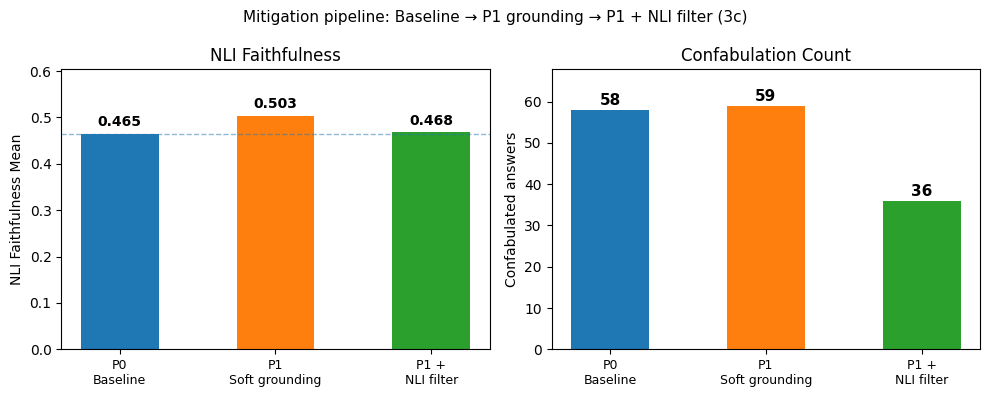


Wallat confabulation cases (5) — pipeline effect:
  [→ FILTERED]  Q: when did the isle of wight become an island
    Base:  The Isle of Wight has always been an island
    Final: I don't know
  [→ P1 changed]  Q: when was the south asian association for regional co-operation (saarc) formed
    Base:  SAARC was formed in 1985
    Final: The South Asian Association for Regional Cooperation
  [→ FILTERED]  Q: who wrote cant get you out of my head lyrics
    Base:  Kylie Minogue wrote the lyrics for "Can't Get You Out of My Head" with
    Final: I don't know
  [→ P1 changed]  Q: where is lord's prayer found in bible
    Base:  The Lord's Prayer is found in the New Testament, specifically in the G
    Final: The Lord's Prayer is not found in the Bible as a separate book
  [→ P1 changed]  Q: where is the tibia and fibula bone located
    Base:  The tibia and fibula bones are located on the inner and outer sides of
    Final: The tibia and fibula bones are located on the inner and outer side

In [40]:
# ── 3c: compare baseline / P1 / P1+filter ────────────────────────────────────
import json, numpy as np, matplotlib.pyplot as plt
import nltk; nltk.download('punkt_tab', quiet=True)
from custom_nli import load_nli_model, evaluate_faithfulness_nli
from context_fidelity import is_refusal
from counterfactual_probe import load_probe_results

try:
    nli_scorer
except NameError:
    nli_scorer = load_nli_model()

with open('/scratch/results/faithfulness_nli.json') as f:
    baseline_nli = json.load(f)
with open('/scratch/results/p2_grounding_sweep/P1_soft.json') as f:
    p1_results = json.load(f)['results']
with open('/scratch/results/p2_fidelity.json') as f:
    filtered_results = json.load(f)['results']

bs   = np.array([r['faithfulness_nli_score'] for r in baseline_nli['results']], dtype=float)
p1m  = evaluate_faithfulness_nli(p1_results,      model=nli_scorer)['per_sample_scores']
fltm = evaluate_faithfulness_nli(filtered_results, model=nli_scorer)['per_sample_scores']
p1s  = np.array(p1m,  dtype=float)
flts = np.array(fltm, dtype=float)

def _mean(arr): return float(np.nanmean(arr))
def _confab(results): return sum(1 for r in results if not is_refusal(r['prediction']))

base_mean     = _mean(bs)
conditions    = ['P0\nBaseline', 'P1\nSoft grounding', 'P1 +\nNLI filter']
nli_means     = [base_mean, _mean(p1s), _mean(flts)]
confab_counts = [_confab(baseline_nli['results']), _confab(p1_results), _confab(filtered_results)]

print(f"{'Condition':<25} {'NLI Mean':>9} {'Delta':>8}  {'Confabulations':>15}")
print('-' * 65)
for cond, nm, cc in zip(conditions, nli_means, confab_counts):
    label = cond.replace('\n', ' ')
    d = nm - base_mean if label != 'P0 Baseline' else 0
    ds = f'{d:+.4f}' if label != 'P0 Baseline' else '   —   '
    print(f"  {label:<23} {nm:9.4f} {ds:>8}  {cc:15d}")

# ── Side-by-side: NLI mean + confabulation count ──────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
x = np.arange(len(conditions))

bars1 = ax1.bar(x, nli_means, color=colors, width=0.5)
ax1.axhline(base_mean, color='#1f77b4', linestyle='--', linewidth=1, alpha=0.5)
for bar, val in zip(bars1, nli_means):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_xticks(x); ax1.set_xticklabels(conditions, fontsize=9)
ax1.set_ylabel('NLI Faithfulness Mean'); ax1.set_title('NLI Faithfulness')
ax1.set_ylim(0, max(nli_means) * 1.2)

bars2 = ax2.bar(x, confab_counts, color=colors, width=0.5)
for bar, val in zip(bars2, confab_counts):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.5,
             str(val), ha='center', va='bottom', fontsize=11, fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(conditions, fontsize=9)
ax2.set_ylabel('Confabulated answers'); ax2.set_title('Confabulation Count')
ax2.set_ylim(0, max(confab_counts) * 1.15)

fig.suptitle('Mitigation pipeline: Baseline → P1 grounding → P1 + NLI filter (3c)', fontsize=11)
plt.tight_layout()
plt.savefig('/scratch/results/p2_3c_comparison.png', dpi=150)
plt.show()

# Wallat confabulation cases
probe = load_probe_results('/scratch/results/faithfulness_counterfactual.json')
confab_qs = {p['question'] for p in probe['per_sample']
             if p['answer_stable'] and not is_refusal(p['original_answer'])}
print(f'\nWallat confabulation cases ({len(confab_qs)}) — pipeline effect:')
for r_b, r_p1, r_f in zip(baseline_nli['results'], p1_results, filtered_results):
    if r_b['question'] in confab_qs:
        tag = '→ FILTERED' if r_f.get('filter_applied') else \
              ('→ P1 changed' if r_p1['prediction'] != r_b['prediction'] else '→ unchanged')
        print(f"  [{tag}]  Q: {r_b['question']}")
        print(f"    Base:  {r_b['prediction'][:70]}")
        print(f"    Final: {r_f['prediction'][:70]}")


### 3c Results — Context-Fidelity Filter Analysis

The NLI output filter was applied on top of the best grounding prompt (P1): any answer with MiniCheck NLI score below 0.5 that is not already a refusal is replaced with *"I don't know"*.

| Condition | NLI Mean | Δ vs baseline | Confabulations |
|---|---|---|---|
| P0 Baseline | 0.4652 | — | 58 |
| P1 Soft grounding | 0.5032 | +0.038 | 59 |
| **P1 + NLI filter** | **0.4676** | **+0.003** | **36** |

**NLI score is the wrong metric for 3c.** The filter replaced 23 answers with *"I don't know"*, dropping confabulations from 59 to 36 (−38%). Yet the NLI mean fell back from P1's 0.503 toward baseline (0.468). The reason: *"I don't know"* is not entailed by any retrieved chunk, so MiniCheck scores it near 0 — identical to the confabulated answer it replaced. The metric cannot distinguish between *"model asserted a wrong fact"* and *"model correctly abstained"*.

**The confabulation count is the right metric for 3c**, and the right-hand plot makes this visible: P1 + NLI filter reduces confabulations by 38% (58 → 36), a clear improvement in generation faithfulness even though the NLI number does not reflect it.

**Effect on the 5 Wallat-probe confabulation cases:**
- *Isle of Wight* and *Kylie Minogue lyrics* — filtered successfully
- *SAARC* and *Lord's Prayer* — P1 grounding prompt already changed the model's behaviour before the filter
- *Tibia/fibula* — slipped through (MiniCheck scored the leg-bone claim ≥ 0.5 against the medial meniscus chunk)

The filter also caught 18 retrieval-failure cases that produced confident wrong answers rather than refusals.

**Choosing the best configuration.** The two metrics recommend different winners:
- For **NLI faithfulness score**: P1 alone (+0.038) — the filter's refusals are penalised equally to the confabulations they replace.
- For **confabulation reduction**: P1 + NLI filter (−38%) — the confabulation plot is the evidence.

Since the research question is *"does the generator faithfully use retrieved context?"*, confabulation rate is the more meaningful metric. **P1 + NLI filter is the recommended final configuration**, with the caveat that standard NLI-based evaluation underestimates its effect.


## 4. Results Summary